<a href="https://colab.research.google.com/github/George7531/Portfolio_Management/blob/main/Group_19296_MScFE_652_Portfolio_Management_Project_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Code Book:**

##Group Work Project # 2
###GROUP NUMBER: 19296
####Group members:

- Duy Vo
- George Immanuel
- Sing Chun Lee


#### Import Required Packages

In [1]:
# This block import all required python packages for running this notebook
import numpy as np                      # numpy
import matplotlib.pyplot as plt         # for plotting
import math                             # math lib
import pandas as pd                     # for storing data in the DataFrame
import pandas_datareader.data as web
from scipy.optimize import minimize     # for minimizing
import yfinance as yf                   # yfinance library
from scipy.cluster.hierarchy import linkage, dendrogram, leaves_list # for clustering
from scipy.spatial.distance import squareform # error function



# Data Preperation and Description

We chose 'TSLA', 'WMT', 'BAC', 'GS', 'LLY', 'MRK', 'GOOG', 'META', 'AAPL', 'XOM', and we split the data set at 2025-10-01. i.e., training: 2024-01-10 to 2025-09-30, and testing: 2025-10-01 to 2025-12-31.

In [2]:
# Define parameters
tickers = ['TSLA', 'WMT', 'BAC', 'GS', 'LLY', 'MRK', 'GOOG', 'META', 'AAPL', 'XOM']
BENCHMARK = "^GSPC"
in_sample_start = '2024-01-01' # updated to 2024-01-01 as we agreed
in_sample_end = '2025-09-30'
out_sample_start = '2025-10-01'
out_sample_end = '2025-12-31'
kfold_start = '2024-01-01'
kfold_end = '2025-12-31'
num_trading_days = 252 # Following the standard, assume we have 252 trading days a year

# 1. Download using yfinance
# Using auto_adjust=False
raw_data = yf.download(
    tickers + [BENCHMARK],
    start='2023-12-25', # Include an additional week before our sample start date
    end='2026-01-01', # the end is exclusive, we should use 2026-01-01 so 2025-12-31 is included
    auto_adjust=False
)

adj_close = raw_data['Close']

# Calculate simple daily percentage returns
daily_returns = adj_close.pct_change().dropna(how='all').dropna()

# Normalize the data for alignment with Fama-French data
daily_returns.index = pd.to_datetime(daily_returns.index).tz_localize(None).normalize()

# In-Sample and Out-of-Sample subsets
returns_in_sample = daily_returns.loc[in_sample_start:in_sample_end]
returns_out_sample = daily_returns.loc[out_sample_start:out_sample_end]
returns_kfold = daily_returns.loc[kfold_start:kfold_end]

print(f"In-Sample Observations: {len(returns_in_sample)} days")
print(f"Out-of-Sample Observations: {len(returns_out_sample)} days")
print(f"K-fold Observations: {len(returns_kfold)} days")

# 2. Download Fama-French 5-Factor Daily Data
ff5_daily = web.DataReader('F-F_Research_Data_5_Factors_2x3_daily', 'famafrench', start='2024-01-01', end='2026-01-01')[0]
ff5_daily.index = ff5_daily.index.to_timestamp()

# Convert from percentages to decimals
ff5_daily = ff5_daily / 100.0

# Normalize the data
ff5_daily.index = pd.to_datetime(ff5_daily.index).tz_localize(None).normalize()

# Partition factor data
ff_in_sample = ff5_daily.loc[in_sample_start:in_sample_end]
ff_out_sample = ff5_daily.loc[out_sample_start:out_sample_end]
ff_kfold_sample = ff5_daily.loc[kfold_start:kfold_end]

print("\nFama-French Data Sample:")
print(pd.concat([ff_in_sample.head(2), ff_out_sample.tail(3)]))

[*********************100%***********************]  11 of 11 completed


In-Sample Observations: 438 days
Out-of-Sample Observations: 64 days
K-fold Observations: 502 days

Fama-French Data Sample:
            Mkt-RF     SMB     HML     RMW     CMA      RF
Date                                                      
2024-01-02 -0.0070 -0.0025  0.0079  0.0067  0.0059  0.0002
2024-01-03 -0.0101 -0.0192 -0.0010  0.0036 -0.0021  0.0002
2025-12-29 -0.0041 -0.0015  0.0007  0.0032  0.0003  0.0002
2025-12-30 -0.0020 -0.0049  0.0029  0.0036  0.0014  0.0002
2025-12-31 -0.0076  0.0006 -0.0010 -0.0007 -0.0004  0.0002


In [ ]:
# Standard Metric Function
def evaluate_portfolio(weights, test_ret_df, rf=0.0):
    """
    Standard Metric Function calculating:
    - Cumulative Return (%)
    - Annualized Sharpe Ratio
    - Maximum Drawdown (%)
    - 95%-cVaR (%)
    - Annualized Sortino Ratio
    """
    if isinstance(weights, (list, np.ndarray)):
        p_returns = test_ret_df.values @ weights
    else:
        p_returns = test_ret_df.values

    # 1. Cumulative Return
    cum_ret = np.prod(1 + p_returns) - 1.0

    # 2. Annualized Sharpe Ratio
    mean_daily = np.mean(p_returns)
    std_daily = np.std(p_returns, ddof=1)
    sharpe = (mean_daily - rf) / std_daily * np.sqrt(252) if std_daily > 0 else 0.0

    # 3. Maximum Drawdown
    wealth = np.cumprod(1 + p_returns)
    peak = np.maximum.accumulate(wealth)
    drawdowns = (peak - wealth) / peak
    max_dd = np.max(drawdowns)

    # 4. 95%-cVaR (Expected Shortfall)
    var_95 = np.percentile(p_returns, 5)
    cvar_95 = -np.mean(p_returns[p_returns <= var_95])

    # 5. Annualized Sortino Ratio
    downside_returns = p_returns[p_returns < rf]
    downside_std = np.sqrt(np.mean(downside_returns**2)) if len(downside_returns) > 0 else 1e-6
    sortino = (mean_daily - rf) / downside_std * np.sqrt(252) if downside_std > 0 else 0.0

    return {
        'Cumulative Return (%)': cum_ret * 100,
        'Annualized Sharpe': sharpe,
        'Max Drawdown (%)': max_dd * 100,
        '95%-cVaR (%)': cvar_95 * 100,
        'Annualized Sortino': sortino
    }

print("Standard evaluate_portfolio function registered.")

Standard evaluate_portfolio function registered.


# Step 1: Optimal Kelly Portfolio & Constrained Optimization

In [28]:
import cvxpy as cvx

# Filter in-sample returns to only include our 10 stock tickers
mu_train = returns_in_sample[tickers].mean().values
Sigma_train = returns_in_sample[tickers].cov().values

# Unconstrained Analytical Kelly Portfolio: w = inv(Sigma) * mu
inv_Sigma = np.linalg.pinv(Sigma_train)
w_unconstrained_raw = inv_Sigma @ mu_train
w_unconstrained_normalized = w_unconstrained_raw / np.sum(w_unconstrained_raw)

# Constrained Kelly Portfolio (w_i <= 0.20, w_i >= 0, sum(w) = 1.0)
w_var = cvx.Variable(len(tickers))
objective = cvx.Maximize(w_var.T @ mu_train - 0.5 * cvx.quad_form(w_var, Sigma_train))
constraints = [
    cvx.sum(w_var) == 1.0,
    w_var >= 0.0,
    w_var <= 0.20
]
prob = cvx.Problem(objective, constraints)
prob.solve()
w_constrained = w_var.value

# Display Weights Comparison
df_step1_weights = pd.DataFrame({
    'Unconstrained Raw': w_unconstrained_raw,
    'Unconstrained Normalized (%)': w_unconstrained_normalized * 100,
    'Constrained (w_i <= 20%) (%)': w_constrained * 100
}, index=tickers)

print("STEP 1 KELLY PORTFOLIO WEIGHTS")
print(df_step1_weights.round(2))

STEP 1 KELLY PORTFOLIO WEIGHTS
      Unconstrained Raw  Unconstrained Normalized (%)  \
TSLA              -0.22                         -2.25   
WMT                7.87                         79.58   
BAC               -2.15                        -21.72   
GS                 4.58                         46.34   
LLY                0.64                          6.51   
MRK               -2.95                        -29.86   
GOOG               2.21                         22.33   
META               1.12                         11.29   
AAPL              -2.02                        -20.43   
XOM                0.81                          8.22   

      Constrained (w_i <= 20%) (%)  
TSLA                          20.0  
WMT                           20.0  
BAC                           -0.0  
GS                            20.0  
LLY                           -0.0  
MRK                           -0.0  
GOOG                          20.0  
META                          20.0  
AAPL    

In [ ]:
print(df_kelly_weights.to_markdown())

|      |   Unconstrained Raw |   Unconstrained Normalized (%) |   Constrained (w_i <= 20%) (%) |
|:-----|--------------------:|-------------------------------:|-------------------------------:|
| TSLA |           -0.222248 |                       -2.24798 |                   20.0001      |
| WMT  |            7.86738  |                       79.5763  |                   20           |
| BAC  |           -2.14763  |                      -21.7227  |                   -1.50499e-05 |
| GS   |            4.58175  |                       46.3431  |                   20           |
| LLY  |            0.64351  |                        6.50892 |                   -3.87227e-05 |
| MRK  |           -2.95234  |                      -29.8621  |                   -3.88485e-05 |
| GOOG |            2.20721  |                       22.3253  |                   20           |
| META |            1.11586  |                       11.2866  |                   20           |
| AAPL |           -2.01998  |

# Step 2: Out-Of-Sample Performance Evaluation (Q4 2025)

In [ ]:
# Slice Test period returns (2025-10-01 to 2025-12-31)
test_returns = returns_out_sample[tickers]
gspc_test_returns = returns_out_sample['^GSPC']

# Evaluate Portfolios
eval_full = evaluate_portfolio(w_constrained, test_returns)
eval_half = evaluate_portfolio(0.5 * w_constrained, test_returns)
eval_double = evaluate_portfolio(2.0 * w_constrained, test_returns)
eval_gspc = evaluate_portfolio(1.0, gspc_test_returns)

df_step2_results = pd.DataFrame([
    eval_full,
    eval_half,
    eval_double,
    eval_gspc
], index=['Full Kelly (1.0x)', 'Half Kelly (0.5x)', 'Double Kelly (2.0x)', 'S&P 500 Benchmark (^GSPC)'])

print("=== STEP 2 OUT-OF-SAMPLE PERFORMANCE & RISK COMPARISON ===")
print(df_step2_results.round(2))

=== STEP 2 OUT-OF-SAMPLE PERFORMANCE & RISK COMPARISON ===
                           Cumulative Return (%)  Annualized Sharpe  \
Full Kelly (1.0x)                           7.88               1.65   
Half Kelly (0.5x)                           3.99               1.65   
Double Kelly (2.0x)                        15.31               1.65   
S&P 500 Benchmark (^GSPC)                   2.35               0.79   

                           Max Drawdown (%)  95%-cVaR (%)  Annualized Sortino  
Full Kelly (1.0x)                      6.52          2.47                1.64  
Half Kelly (0.5x)                      3.28          1.23                1.64  
Double Kelly (2.0x)                   12.86          4.94                1.64  
S&P 500 Benchmark (^GSPC)              5.11          1.77                0.68  


In [ ]:
print(df_step2_results.to_markdown())

|                           |   Cumulative Return (%) |   Annualized Sharpe |   Max Drawdown (%) |   95%-cVaR (%) |   Annualized Sortino |
|:--------------------------|------------------------:|--------------------:|-------------------:|---------------:|---------------------:|
| Full Kelly (1.0x)         |                 7.88281 |            1.65079  |            6.51927 |        2.46884 |             1.63573  |
| Half Kelly (0.5x)         |                 3.98745 |            1.65079  |            3.28101 |        1.23442 |             1.63573  |
| Double Kelly (2.0x)       |                15.3119  |            1.65079  |           12.8592  |        4.93768 |             1.63573  |
| S&P 500 Benchmark (^GSPC) |                 2.34793 |            0.786337 |            5.11009 |        1.77432 |             0.676254 |


#Step 3: K-Fold Cross-Validation Backtesting (2024-2025)

In [ ]:
# Full 2-Year Returns (2024-01-01 to 2025-12-31)
full_returns = returns_kfold[tickers]

K = 5
n_samples = len(full_returns)
fold_size = n_samples // K

kfold_list = []
for k in range(K):
    test_idx = list(range(k * fold_size, (k + 1) * fold_size if k < K - 1 else n_samples))
    train_idx = [i for i in range(n_samples) if i not in test_idx]

    train_fold = full_returns.iloc[train_idx]
    test_fold = full_returns.iloc[test_idx]

    # Solve Constrained Kelly on train_fold
    mu_k = train_fold.mean().values
    Sigma_k = train_fold.cov().values
    w_var_k = cvx.Variable(len(tickers))
    prob_k = cvx.Problem(cvx.Maximize(w_var_k.T @ mu_k - 0.5 * cvx.quad_form(w_var_k, Sigma_k)),
                        [cvx.sum(w_var_k) == 1.0, w_var_k >= 0.0, w_var_k <= 0.20])
    prob_k.solve()
    w_k = w_var_k.value

    res_k = evaluate_portfolio(w_k, test_fold)
    res_k['Fold'] = f"Fold {k+1} ({test_fold.index.min().strftime('%Y-%m-%d')} to {test_fold.index.max().strftime('%Y-%m-%d')})"
    kfold_list.append(res_k)

df_kfold_summary = pd.DataFrame(kfold_list).set_index('Fold')
df_kfold_mean_std = pd.DataFrame({
    'Cumulative Return (%)': [df_kfold_summary['Cumulative Return (%)'].mean(), df_kfold_summary['Cumulative Return (%)'].std()],
    'Annualized Sharpe': [df_kfold_summary['Annualized Sharpe'].mean(), df_kfold_summary['Annualized Sharpe'].std()],
    'Max Drawdown (%)': [df_kfold_summary['Max Drawdown (%)'].mean(), df_kfold_summary['Max Drawdown (%)'].std()],
    '95%-cVaR (%)': [df_kfold_summary['95%-cVaR (%)'].mean(), df_kfold_summary['95%-cVaR (%)'].std()],
    'Annualized Sortino': [df_kfold_summary['Annualized Sortino'].mean(), df_kfold_summary['Annualized Sortino'].std()]
}, index=['Mean across Folds', 'Std across Folds'])

df_step3_full = pd.concat([df_kfold_summary, df_kfold_mean_std])
print("=== STEP 3 K-FOLD CROSS-VALIDATION RESULTS ===")
print(df_step3_full.round(2))

=== STEP 3 K-FOLD CROSS-VALIDATION RESULTS ===
                                   Cumulative Return (%)  Annualized Sharpe  \
Fold 1 (2024-01-02 to 2024-05-23)                   7.19               1.14   
Fold 2 (2024-05-24 to 2024-10-16)                  16.52               1.98   
Fold 3 (2024-10-17 to 2025-03-13)                   1.07               0.23   
Fold 4 (2025-03-14 to 2025-08-06)                  22.66               1.71   
Fold 5 (2025-08-07 to 2025-12-31)                  21.69               2.74   
Mean across Folds                                  13.82               1.56   
Std across Folds                                    9.40               0.94   

                                   Max Drawdown (%)  95%-cVaR (%)  \
Fold 1 (2024-01-02 to 2024-05-23)              5.09          2.06   
Fold 2 (2024-05-24 to 2024-10-16)             13.65          3.32   
Fold 3 (2024-10-17 to 2025-03-13)             18.20          3.40   
Fold 4 (2025-03-14 to 2025-08-06)           

# Step 4b: Improvements using Culstering

To begin, we computer the hierarchical clustering as we learned in the lessons.

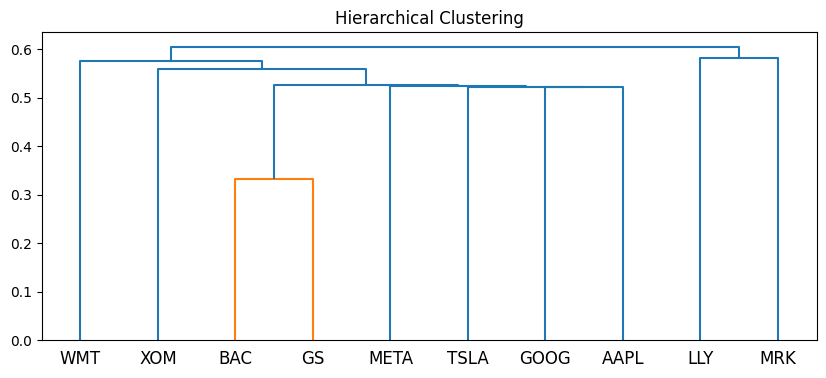

Orders:  ['WMT', 'XOM', 'BAC', 'GS', 'META', 'TSLA', 'GOOG', 'AAPL', 'LLY', 'MRK']


In [ ]:
# Hierarchical Clustering
train = returns_in_sample[tickers]
test = returns_out_sample[tickers]

# Computer the coveraince and correlation matrices
cov = train.cov()
corr = train.corr()

# Convert the correlations into distances
distances = np.sqrt((1 - corr) / 2)
np.fill_diagonal(distances.values, 0) # to itself should be 0 distance

# Single linkage hierarchical clustering
links = linkage(squareform(distances.values), method="single")

# Show the current linkages
plt.figure(figsize=(10, 4))
dendrogram(links, labels=tickers)
plt.title("Hierarchical Clustering")
plt.show()

# Order the stocks by clusters
ordered_tickers = [tickers[i] for i in leaves_list(links)]
print("Orders: ", ordered_tickers)

Now, we can compare the results. First, we compute the weights using HRP and MVO.

In [ ]:
# Compute the HRP weights through recursive bisection
hrp_weights = pd.Series(1.0, index=ordered_tickers)
clusters = [ordered_tickers]

while clusters:
  clusters = [part for group in clusters if len(group) > 1 for part in (group[:len(group)//2], group[len(group)//2:])]

  for i in range(0, len(clusters), 2):
    left, right = clusters[i], clusters[i+1]
    left_cov = cov.loc[left, left].values
    right_cov = cov.loc[right, right].values

    left_ivp = 1 / np.diag(left_cov)
    left_ivp /= left_ivp.sum()
    right_ivp = 1 / np.diag(right_cov)
    right_ivp /= right_ivp.sum()

    left_var = left_ivp @ left_cov @ left_ivp
    right_var = right_ivp @ right_cov @ right_ivp

    alpha = right_var / (right_var + left_var)

    hrp_weights.loc[left] *= alpha
    hrp_weights.loc[right] *= [1 - alpha]

# Compute MVO weights
mean = train.mean().values * num_trading_days
cov_mov = cov.values * num_trading_days
n = len(tickers)

mvo_weights = minimize(lambda w: 0.5 * (w @ cov_mov @ w) - w @ mean, np.ones(n) / n, method='SLSQP', constraints={'type': 'eq', 'fun': lambda w: w.sum() - 1}, bounds=[(0, 1)] * n)
assert mvo_weights.success, mvo_weights.message

# Put them in a data frame
weights = pd.DataFrame({'MVO': mvo_weights.x, 'HRP': hrp_weights.reindex(tickers).values, 'Uniform': np.ones(n) / n}, index=tickers)

# Display the results in percentages
print((weights * 100).round(2))

        MVO    HRP  Uniform
TSLA  20.21   2.25     10.0
WMT    0.00  20.22     10.0
BAC    0.00   8.96     10.0
GS    34.21   4.92     10.0
LLY    0.00   6.13     10.0
MRK    0.00  12.38     10.0
GOOG   0.00  10.73     10.0
META  45.58   2.92     10.0
AAPL   0.00  12.31     10.0
XOM    0.00  19.19     10.0


Last, we used backtesting to compare the performances

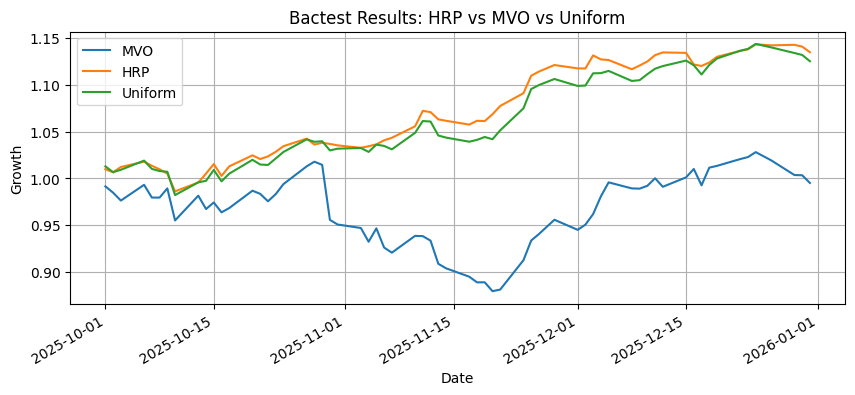

         Cumulative Return (%)  Sharpe Ratio  Max Drawdown (%)  95%-CVaR (%)  \
MVO                      -0.49         -0.17            -13.59          3.51   
HRP                      13.48          4.22             -3.12          1.28   
Uniform                  12.51          3.18             -3.61          1.51   

         Sortino Ratio  
MVO              -0.00  
HRP               0.11  
Uniform           0.08  


In [ ]:
# Compute the daily returns
portfolio_returns = test @ weights

# Cumulative growth
growth = (1 + portfolio_returns).cumprod()
growth.plot(figsize=(10, 4))
plt.title("Bactest Results: HRP vs MVO vs Uniform")
plt.ylabel("Growth")
plt.grid(True)
plt.show()

# Performance metrics
rf = ff_out_sample['RF'].reindex(test.index)

results = {}
for name in portfolio_returns.columns:
  r = portfolio_returns[name]
  excess = r - rf
  wealth = (1 + r).cumprod()
  peak = np.maximum.accumulate(np.r_[1.0, wealth.values])[1:]
  drawdown = wealth.values / peak - 1
  downside = np.minimum(excess, 0)
  var_95 = r.quantile(0.05)

  results[name] = {
      'Cumulative Return (%)': (wealth.iloc[-1] - 1) * 100,
      'Sharpe Ratio': excess.mean() / excess.std() * np.sqrt(num_trading_days),
      'Max Drawdown (%)': drawdown.min() * 100,
      '95%-CVaR (%)': -r[r <= var_95].mean() * 100,
      'Sortino Ratio': excess.mean() / np.sqrt((downside**2).mean() * np.sqrt(num_trading_days))
  }

performances = pd.DataFrame(results).T
print(performances.round(2))

Our experiment found that Hierarchical Risk Parity (HRP) significantly outperformed standard Mean-Variance Optimization (MVO) over the out-of-sample observations. HRP obtained a 13.48% cumulative return and a 4.22 Sharpe ratio, while MVO had negative returns (-0.49%) and a negative Sharpe ratio (-0.17). Therefore, it suggests that HRP indeed improves portfolio performance. However, we also included uniform weighting in the comparison, and we found that uniform weighting, in fact, performed similarly to HRP. It made us wonder if a simple uniform distribution is sufficiently good. Our experiment is limited to these ten stocks. More data could provide better interpretations.

# George's work:


# Step 4c: Detoning

Financial assets are often correlated because they are exposed to some common systematic factors, it could be recession or recent policy changes or whatever that makes all assets in the market to behave like they are all same. A simple example would be the oil syndicate deciding to change the price of fuel, since majority of vehicles use petrol/diesel for locomotion, it will simultaneously affect the prices of all assets from sandals we wear, to colab we use to write this piece down, to colors they use to make floral patterns on their porches(Indian cultural custom) likewise in times of crisis all assets from real estates, to IT stocks, to agricultural companies are affected and heavily correlated and nose dive regardless of their locations and geography in the globe.

How do we deal with this?
When we calculate the correlation matrix of asset returns, the largest eigenvalue and its corresponding eigenvector often capture this common market behaviour. This is called as the market mode. But the things is the market factor that is common among assets would overstate or misreport the actual specific dependency or correlation between companies for example lets say Nvidia and AMD dealing with semiconductors and chips they have some dependency between them that is prior to including the common market factor such as oil price was 0.5 correlation but after including the market factor it might elevate to 0.91 or some other bizzare number that obscures the actual dependency between things we measure. This is where Detoning helps.

Detoning addresses this problem by removing the contribution of the dominant market eigencomponent from the correlation matrix.This allows the remaining correlation structure to reflect more of the relative relationships between assets rather than their common market exposure (López de Prado, 2020).

The steps to detoning are way simpler with statistical packages such as numpy or scipy, I just want to state here the steps in words.

* step1: Take the correlation matrix of our portfolio. Constraint is this correlation matrix must be postive semi-definite meaning its eigen values must be greater than or equal to 0.

* step2: Take eigen decomposition to get eigen vectors and their eigen values$ Correl = V \Lambda V^T $.  Arrange the eigen values and corresponding eigen vectors in descending order to identify the largest contributer(s) as front guardians ($\lambda_1 \geq \lambda_2 \geq \dots \geq \lambda_N$). The largest eigen value ($ \lambda_1$) and its vector($v_1$) typically represent major market factor's contribution.

* step3: In order to remove the effect of this common factor from our correlation matrix, we have to subtract this largest(er) eigen value and vector from  the original covariance matrix such as: $ \hat{correl} = correl - \lambda_1 v_1 v_1^T $, if we want to remove q major factors then we will have to do: $$\hat{Correl} = Correl - \sum_{i=1}^{q} \lambda_i v_i v_i^\top$$

* step4: Then we have to normalize this $ \hat{correl} $ to make it have 1 as its diagonal entries because when we did the transformation(by removing the major contributers by subtraction) the diagonal entries may have gotten altered, so no longer representative of self-correlation, so we do this by taking the diagonal elements of $ \hat{Correl} $ and then take inverse square root of each entry like this:
$$D^{-1/2} = \begin{pmatrix} \frac{1}{\sqrt{\hat{Correl}_{11}}} & 0 & \cdots & 0 \\  0 & \frac{1}{\sqrt{\hat{Correl}_{22}}} & \cdots & 0 \\  \vdots & \vdots & \ddots & \vdots \\  0 & 0 & \cdots & \frac{1}{\sqrt{\hat{Correl}_{NN}}} \end{pmatrix}$$

to finally get our detoned correlated matrix:


$$ Correl_{\text{detoned}} = D^{-1/2} \hat{Correl} D^{-1/2} $$

This detoning technique can be super useful in hierarchical risk clustering or for risk seperation especially during times of crisis when assets in our portfolio would exhibit higher and closer correlations like 0.91,0.93 and so on.. during which time we can remove the common market factor(s) contribution and find how each individual asset are correlated in the absence of that common factor.



# Step 5:

Our plan is use those 10 stocks and check whether reducing noise by denoising, removing dominant market contributions by detoning, and rearranging assets into hierarchical clusters can improve portfolio allocation compared to traditional optimization approach.

we first calculate correlation matrix of our assets and then perform Eigen decompostion on it.

plan:
1. create a function to perform Eigen decomposition on our correlation matrix and to check if it is positive semi definite set a threshold and check if the minimum eigen value is not below it, they should not be below zero.
2. Calculate the correlation matrix.
3. make the correlation matrix symmetric
4. Return the correlation, covariance, and standard deviations

In [3]:
def nearest_correlation_from_psd(A, tol=1e-12):
    A=(np.asarray(A)+np.asarray(A).T)/2
    vals,vecs=np.linalg.eigh(A)
    if vals.min() < -1e-8: raise ValueError('Matrix is materially non-PSD')
    A=(vecs*np.maximum(vals,0))@vecs.T
    diag=np.diag(A)
    if np.any(diag<=tol): raise ValueError('Nonpositive diagonal prevents renormalization')
    corr=A/np.sqrt(np.outer(diag,diag))
    return (corr+corr.T)/2

def sample_structures(returns):
    cov=returns.cov().to_numpy()
    std=np.sqrt(np.diag(cov)); corr=cov/np.outer(std,std)
    return nearest_correlation_from_psd(corr),cov,std

Now denoising:


* we want to check if the eigen value of our correlation matrix is less than threshold defined by $ (1 + \sqrt{q})^2 $ where $ q = \frac{\text{number of columns in our correlation matrix}}{\text{number of rows in our returns dataframe}} $.
* if any of eigen value in the eigen value vector is found being less than or equal to this threshold: $ (1 + \sqrt{q})^2 $ then it is considered noise and we have to replace that eigen value with the average of eigen values in our eigen value vector, and then we reconstruct our correlation with this noise removed eigen values.


In [4]:
def mp_denoise(corr, n_obs):
    n=corr.shape[0]; q=n/n_obs
    if q>=1: raise ValueError('MP implementation assumes number of dates > number of assets')
    threshold=(1+np.sqrt(q))**2
    val,vec=np.linalg.eigh(corr)
    is_noise=val<=threshold
    if not is_noise.any(): raise ValueError('No noise eigenvalues under fixed MP threshold')
    clipped=val.copy(); clipped[is_noise]=val[is_noise].mean()
    den=(vec*clipped)@vec.T
    den=nearest_correlation_from_psd(den)
    return den, {'q':q,'mp_upper':threshold,'n_noise':int(is_noise.sum()),
                 'n_signal':int((~is_noise).sum()),'eig_before':val[::-1],
                 'eig_clipped_pre_normalization':clipped[::-1]}

Detoning:
* I already explained at length about how detoning works, so I'm going to just stroke my brush ever so slightly here.
* Take the correlation matrix, find the eigen decomposition, and remove those high eigen values and their corresponding eigen vectors, and reconstruct our correlation matrix again.

In [5]:
def detone(corr,n_modes=1):
    val,vec=np.linalg.eigh(corr)
    if n_modes<1 or n_modes>=len(val): raise ValueError('Invalid number of market modes')
    indices=np.argsort(val)[::-1][:n_modes]
    market=(vec[:,indices]*val[indices])@vec[:,indices].T
    resid=(corr-market); resid=(resid+resid.T)/2
    if np.min(np.diag(resid))<=1e-12: raise ValueError('Detoning yielded nonpositive residual variance')
    return nearest_correlation_from_psd(resid), {'removed_share':float(val[indices].sum()/val.sum()),
                                                   'removed_eigenvalues':val[indices]}

covariance matrix:
* Multiply our correlation matrix by outer product of volatilities.


In [6]:
def to_cov(corr,std):
  return (corr*np.outer(std,std))

Put it all together.
first denoise and then detone our correation matrix and then ensure the diagonal of that matrix are all close to 1 indicating self correlation, eigen values are all greater than 0 and detoned correlation matrix should be singular; it's determinant must be zero.

In [7]:
def diagnose_matrix(name,c):
    eig=np.linalg.eigvalsh(c)
    return {'matrix':name,'trace':float(np.trace(c)),'min_eigenvalue':float(eig.min()),
            'max_eigenvalue':float(eig.max()),'condition_number_finite':float(eig.max()/max(eig.min(),1e-14)),
            'mean_off_diagonal_corr':float((np.sum(c)-np.trace(c))/(len(c)*(len(c)-1)))}



In [8]:
train = returns_in_sample.loc['2024-01-01':'2025-09-30', tickers].copy()
train.head(5)

Ticker,TSLA,WMT,BAC,GS,LLY,MRK,GOOG,META,AAPL,XOM
Date,,,,,,,,,,
2024-01-02,-0.000241,0.010403,0.006831,0.006558,0.015920,0.038709,-0.009721,-0.021669,-0.035787,0.023805
2024-01-03,-0.040134,0.000063,-0.010915,-0.016765,0.043060,0.013511,0.005732,-0.005256,-0.007488,0.008402
2024-01-04,-0.002181,-0.009667,0.008053,0.003038,-0.005181,0.019517,-0.016529,0.007693,-0.012700,-0.008719
2024-01-05,-0.001849,-0.006656,0.018639,0.009113,0.006591,0.001795,-0.004709,0.013915,-0.004013,0.003030
2024-01-08,0.012464,0.009827,-0.007842,0.006262,0.012093,0.001365,0.022855,0.019065,0.024175,-0.016662


I have changed my plan. I want to see our raw correlation and compare it with our denoised and detoned correlation. This also includes first denoising and then detoning, second detoning and then denoising

In [9]:
# Calculate sample covariance and correlation
c_raw, cov_raw, std = sample_structures(train)

# Denoising using Marchenko-Pastur
c_den, mp_info = mp_denoise(c_raw, len(train))

# Detoning using the first principal component
c_tone, tone_info = detone(c_raw)

# Denoising followed by detoning
c_dt, dt_info = detone(c_den)

# Detoning followed by denoising
c_td, td_info = mp_denoise(c_tone, len(train))

# Store matrices
matrices = {
    'Raw': c_raw,
    'Denoised': c_den,
    'Detoned': c_tone,
    'Denoise -> Detoned': c_dt,
    'Detoned -> Denoised': c_td
}

# Generate diagnostic table
diag_table = pd.DataFrame([
    diagnose_matrix(name, c)
    for name, c in matrices.items()
]).set_index('matrix')

print('Marchenko-Pastur details:')
print({k: v for k, v in mp_info.items() if 'eig_' not in k})

print('\nRaw market explained share:',
      round(tone_info['removed_share'], 4))

# Verify the correlation matrices
assert all(
    np.allclose(np.diag(c), 1, atol=1e-8)
    for c in matrices.values()
), "Some matrices do not have unit diagonals"

assert all(
    np.linalg.eigvalsh(c).min() > -1e-8
    for c in matrices.values()
), "Some matrices are not positive semidefinite"

assert np.linalg.eigvalsh(c_tone).min() < 1e-8, \
    "Detoned matrix should be singular"

print("\nAll matrix assertions passed.")

Marchenko-Pastur details:
{'q': 0.0228310502283105, 'mp_upper': np.float64(1.3250299928360603), 'n_noise': 9, 'n_signal': 1}

Raw market explained share: 0.354

All matrix assertions passed.


In [10]:
# Display results
display(diag_table.round(5))

,trace,min_eigenvalue,max_eigenvalue,condition_number_finite,mean_off_diagonal_corr
matrix,,,,,
Raw,10.0,0.20916,3.53958,1.692317e+01,0.25782
Denoised,10.0,0.58933,3.34100,5.669130e+00,0.24764
Detoned,10.0,0.00000,2.16723,2.167234e+14,-0.10518
Denoise -> Detoned,10.0,0.00000,1.14176,1.141755e+14,-0.10854
Detoned -> Denoised,10.0,0.65569,2.03041,3.096580e+00,-0.01963


* In the raw correlation matrix, 35.39% of variance was being captured by the first eigen value (max_eigenvalue of Raw/10 assets), and when we Denoise and then Detone (Denoise -> Detone) we have that reduced to about 11.41%, so the common market factor's effects are effectively reduced, Nice!
* condition_number_finite	Indicates numerical sensitivity; very large values indicate near-singularity, both our detoned and denoised -> detoned correlation matrixes have got 2.16e+14 and 1.14e+14, so their determinants are zero.
* our mean off-diagonal values (covariances) also changed from 0.25782 to -0.10854 in Denoised to Detoned, have stocks become hedges against one another?

## is our Hypothesis True?

is it really True that largest eigen value(s) correspond to a market factor and that removing it would help us establish if there is a meaningful dependency amongst assets in our portfolio? We saw that our raw correlation matrix had the first Principal component explaining 35.4% something variance (max_eigenvalue) but which stocks or combinations of them contributed to that? and which stocks' correlations change most after detoning them?

I'd like to see first our principal components, next pairwise-correlation changes amongst stocks, then we will do hierarchical clustering and portfolio allocation etc..


First, Eigen vectors are notorious for possessing altering signs; they are directionally bambazooled fellows, we have to fix that first and then find each stock's contribution to this first eigen vector

blueprint:
1. Take eigen decomposition for our raw correlation of assets.
2. Take the first principal component and its eigen value.
3. Keep all the directions they point to the same
4. find how much each stock contributed to this pc1.

In [11]:

eigenvalues, eigenvectors = np.linalg.eigh(c_raw)

# Eigenvalues are ascending, so the last is largest
pc1 = eigenvectors[:, -1].copy()
lambda1 = eigenvalues[-1]

# keep all signs positive
if pc1.sum() < 0:
    pc1 = -pc1

pc1_table = pd.DataFrame({
    'PC1_Loading': pc1,
    'PC1_Contribution_%': 100 * pc1**2
}, index=tickers)

pc1_table = pc1_table.sort_values(
    'PC1_Contribution_%', ascending=False
)

print(f"Largest eigenvalue: {lambda1:.5f}")
print(f"Variance explained: {100*lambda1/len(tickers):.2f}%")
display(pc1_table.round(4))



Largest eigenvalue: 3.53958
Variance explained: 35.40%


,PC1_Loading,PC1_Contribution_%
GS,0.4322,18.6816
BAC,0.3972,15.7776
AAPL,0.3767,14.1886
TSLA,0.3431,11.7752
META,0.3422,11.7086
GOOG,0.3276,10.7341
WMT,0.2711,7.3514
XOM,0.2127,4.5262
LLY,0.1933,3.7357
MRK,0.1233,1.5208


plot it

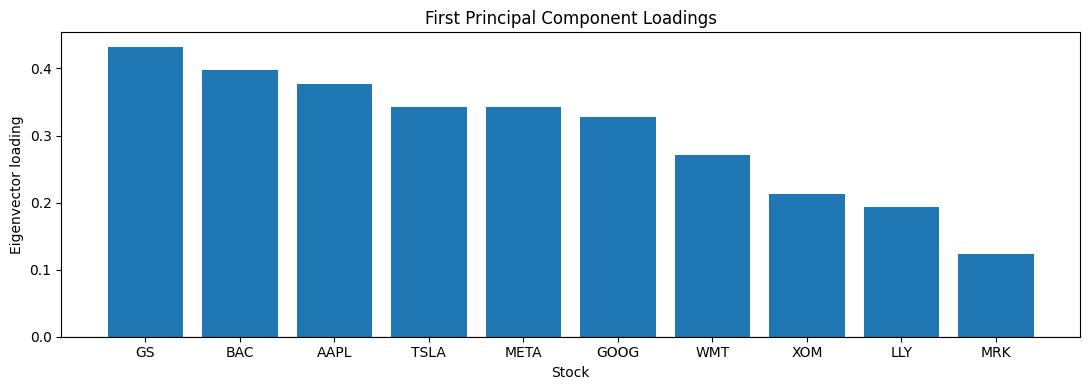

In [12]:
# Plot loadings
plt.figure(figsize=(11, 4))
plt.bar(pc1_table.index, pc1_table['PC1_Loading'])
plt.axhline(0, color='black', linewidth=0.8)
plt.title('First Principal Component Loadings')
plt.ylabel('Eigenvector loading')
plt.xlabel('Stock')
plt.tight_layout()
plt.show()

assert np.isclose(np.sum(pc1**2), 1)
assert np.isclose(pc1_table['PC1_Contribution_%'].sum(), 100)


* Five stocks (GS, BAC, AAPL, TSLA, and META) account for 72.13% of PC1's total variance contribution: 18.68% + 15.78% + 14.19% + 11.78% + 11.71% = 72.13% . Especially Financial companies Goldman sachs(Gs) and Bank of America appear to be the top2 largest contributors of our first principal component, does it mean it is not a market factor but acts as one since GS and BAC might have investments in each of the other stocks in our portfolio creating this halo like common correlation?
* The other stocks like  MRK, LLY, XOM have single digit, below 5% contribution each, so the contribution is almost entirely driven by finance-techishque companies.
* This pc1 is not representative of market factor or is it? does it atleast a representative of s&p 500?




## Compare PC1 with the S&P 500
let's see how the pc1 of s&p 500 compares against our little portfolio pc1.

plans:
1. Get the s&p 500 data from sing chun lee's code.
2. get z scores for returns of our assets in train, so that highly volatile assets do not wag their tails too much and influence our analysis dispropotionately.
3. Get the pc1 scores by matrix multiplying our z score with pc1 we found above.
4. we want to compare this pc1 scores with our s&p 500 by seeing how much they are similar or correlate.


In [13]:
len(daily_returns.loc[train.index, BENCHMARK])

438

There are 438 stocks in our BENCHMARK, not 500 as the name implies, but that won't make our analysis any less better.

In [14]:
# s&p 500 is our benchmark
benchmark = daily_returns.loc[train.index, BENCHMARK]

standardized_returns = (
    train - train.mean()
) / train.std(ddof=1)

pc1_scores = pd.Series(
    standardized_returns.to_numpy() @ pc1,
    index=train.index,
    name='PC1'
)

comparison = pd.concat(
    [pc1_scores, benchmark.rename('SP500')],
    axis=1
).dropna()

pc1_sp500_corr = comparison['PC1'].corr(
    comparison['SP500']
)

print(f"Correlation between PC1 and S&P 500: "f"{pc1_sp500_corr:.4f}")



Correlation between PC1 and S&P 500: 0.9144


wow! that's a substantial correlation. Nice man, Our pc1 is indeed more similar to s&p 500 returns than not!!! the pc1 is a good enough representative of our common market factor.

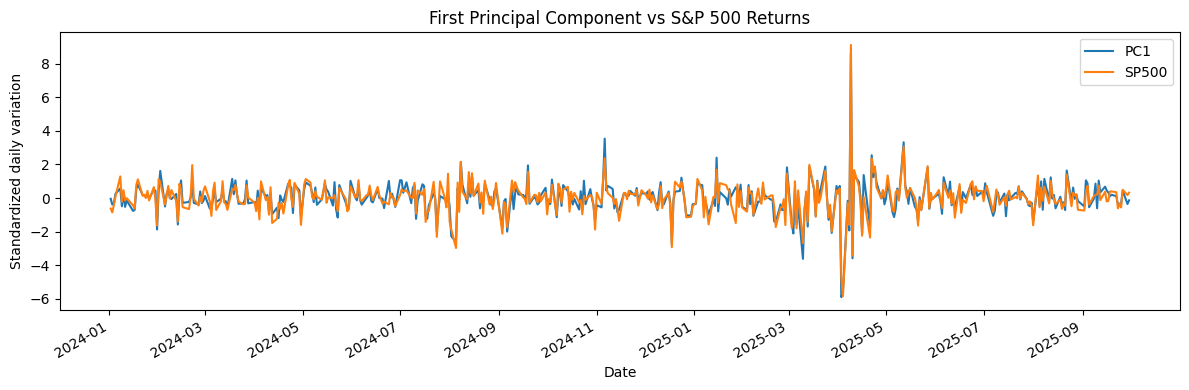

In [15]:
# Normalize for plotting only
normalized = (
    comparison - comparison.mean()
) / comparison.std()

normalized.plot(
    figsize=(12, 4),
    title='First Principal Component vs S&P 500 Returns'
)
plt.ylabel('Standardized daily variation')
plt.tight_layout()
plt.show()




## Which Stock's correlation change?

* Our previous table reported the average correlation, but that is insufficient to understand clustering, we want to which pair of stocks are strongly correlated after removing the first component; we want to inspect whether BAC–GS, LLY–MRK, and GOOG–META remain strongly related after removing the pc1.

* we have removed the effect of pc1 with denoising and detoning, so we'll compare the pair-wise correlation in each of these filtered and un-filtered versions of correlations.





In [16]:

# this is our raw correlation
raw_corr = pd.DataFrame(
    c_raw, index=tickers, columns=tickers
)

# correlation of c_tone or detoned correlation
detoned_corr = pd.DataFrame(
    c_tone, index=tickers, columns=tickers
)

# this is correlation of the matrix that underwent both denoising and detoning.
combined_corr = pd.DataFrame(
    c_dt, index=tickers, columns=tickers
)

# some unique pairs of our 10 stocks.
pairs = [
    ('BAC', 'GS'),
    ('LLY', 'MRK'),
    ('GOOG', 'META'),
    ('AAPL', 'GOOG'),
    ('TSLA', 'META'),
    ('WMT', 'XOM')
]

# create a beautiful DataFrame for it.
pair_table = pd.DataFrame([
    {
        'Pair': f'{a}-{b}',
        'Raw': raw_corr.loc[a, b],
        'Detoned': detoned_corr.loc[a, b],
        'Denoised_Detoned': combined_corr.loc[a, b],
        'Change_after_Detoning':
            detoned_corr.loc[a, b] - raw_corr.loc[a, b]
    }
    for a, b in pairs
]).set_index('Pair')

display(pair_table.round(4))


,Raw,Detoned,Denoised_Detoned,Change_after_Detoning
Pair,,,,
BAC-GS,0.7779,0.4402,-0.1342,-0.3377
LLY-MRK,0.3218,0.2621,-0.0488,-0.0598
GOOG-META,0.4477,0.0845,-0.1312,-0.3632
AAPL-GOOG,0.4562,0.0349,-0.1336,-0.4213
TSLA-META,0.3310,-0.1448,-0.1327,-0.4758
WMT-XOM,0.0617,-0.1808,-0.0956,-0.2425


After just detoning we see the correlation between some assets still maintaining positive numbers but when denoised and detoned relationship between different assets in our portfolio became completely negative as if one would help hedge the other? But will it work in portfolio of any size, our portfolio had only 10 assets in them

Compare original and transformed correlation structures


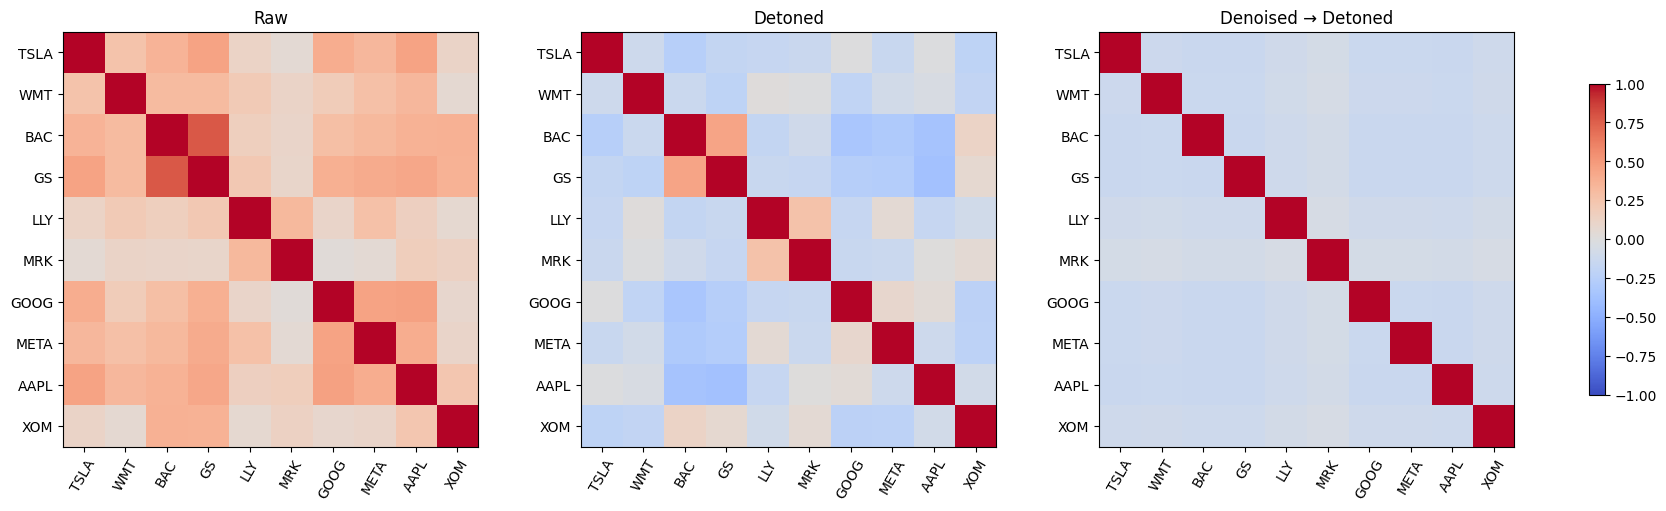

In [17]:


fig, axes = plt.subplots(
    1, 3, figsize=(17, 5), constrained_layout=True
)

for ax, (name, matrix) in zip(
    axes,
    [
        ('Raw', c_raw),
        ('Detoned', c_tone),
        ('Denoised → Detoned', c_dt)
    ]
):
    im = ax.imshow(
        matrix, cmap='coolwarm',
        vmin=-1, vmax=1
    )
    ax.set_title(name)
    ax.set_xticks(range(len(tickers)))
    ax.set_yticks(range(len(tickers)))
    ax.set_xticklabels(tickers, rotation=60)
    ax.set_yticklabels(tickers)

fig.colorbar(im, ax=axes, shrink=0.75)
plt.show()


They behave like completely different opposing entities after denoising and detoned; Correlation is all greyed-out between assets in our portfolio.

## Compare hierarchical clustering:

We can now do the HRP dendrogram.

first I'll create cluster_linkage() function to make the similar assets sit close to each other.

plan:
1. first I'll Convert correlation matrix to distance matrix. Our cluster_linkage function will take the correlation and find the distance based on this formula: $ \sqrt{max(0,(1-\text{correlation})/2) } $, It looks a ReLU, isn't it?
2. Then we make sure our distance matrix is  symmetric and has zeros in its diagonal.
3. And We apply squareform which  Converts our symmetric distance matrix into a 1D condensed array of its upper-triangular entries.
4. Then we put the linkage function to use which builds this beautiful hierarchical trees based on how close the values of our assets are in the distance matrix.
5. And then we have to get the ordering from left to right from the bottom of our hierarchical tree.

In [18]:
def cluster_linkage(c):
    distance = np.sqrt(np.maximum(0, (1 - c) / 2))
    distance = (distance + distance.T) / 2
    np.fill_diagonal(distance, 0)
    condensed = squareform(distance, checks=True)
    z = linkage(condensed, method='single')
    order = leaves_list(z)
    return z, order

Lets create those trees for each of our different versions of correlated matrices; raw, denoised, detoned, and denoised to detoned.

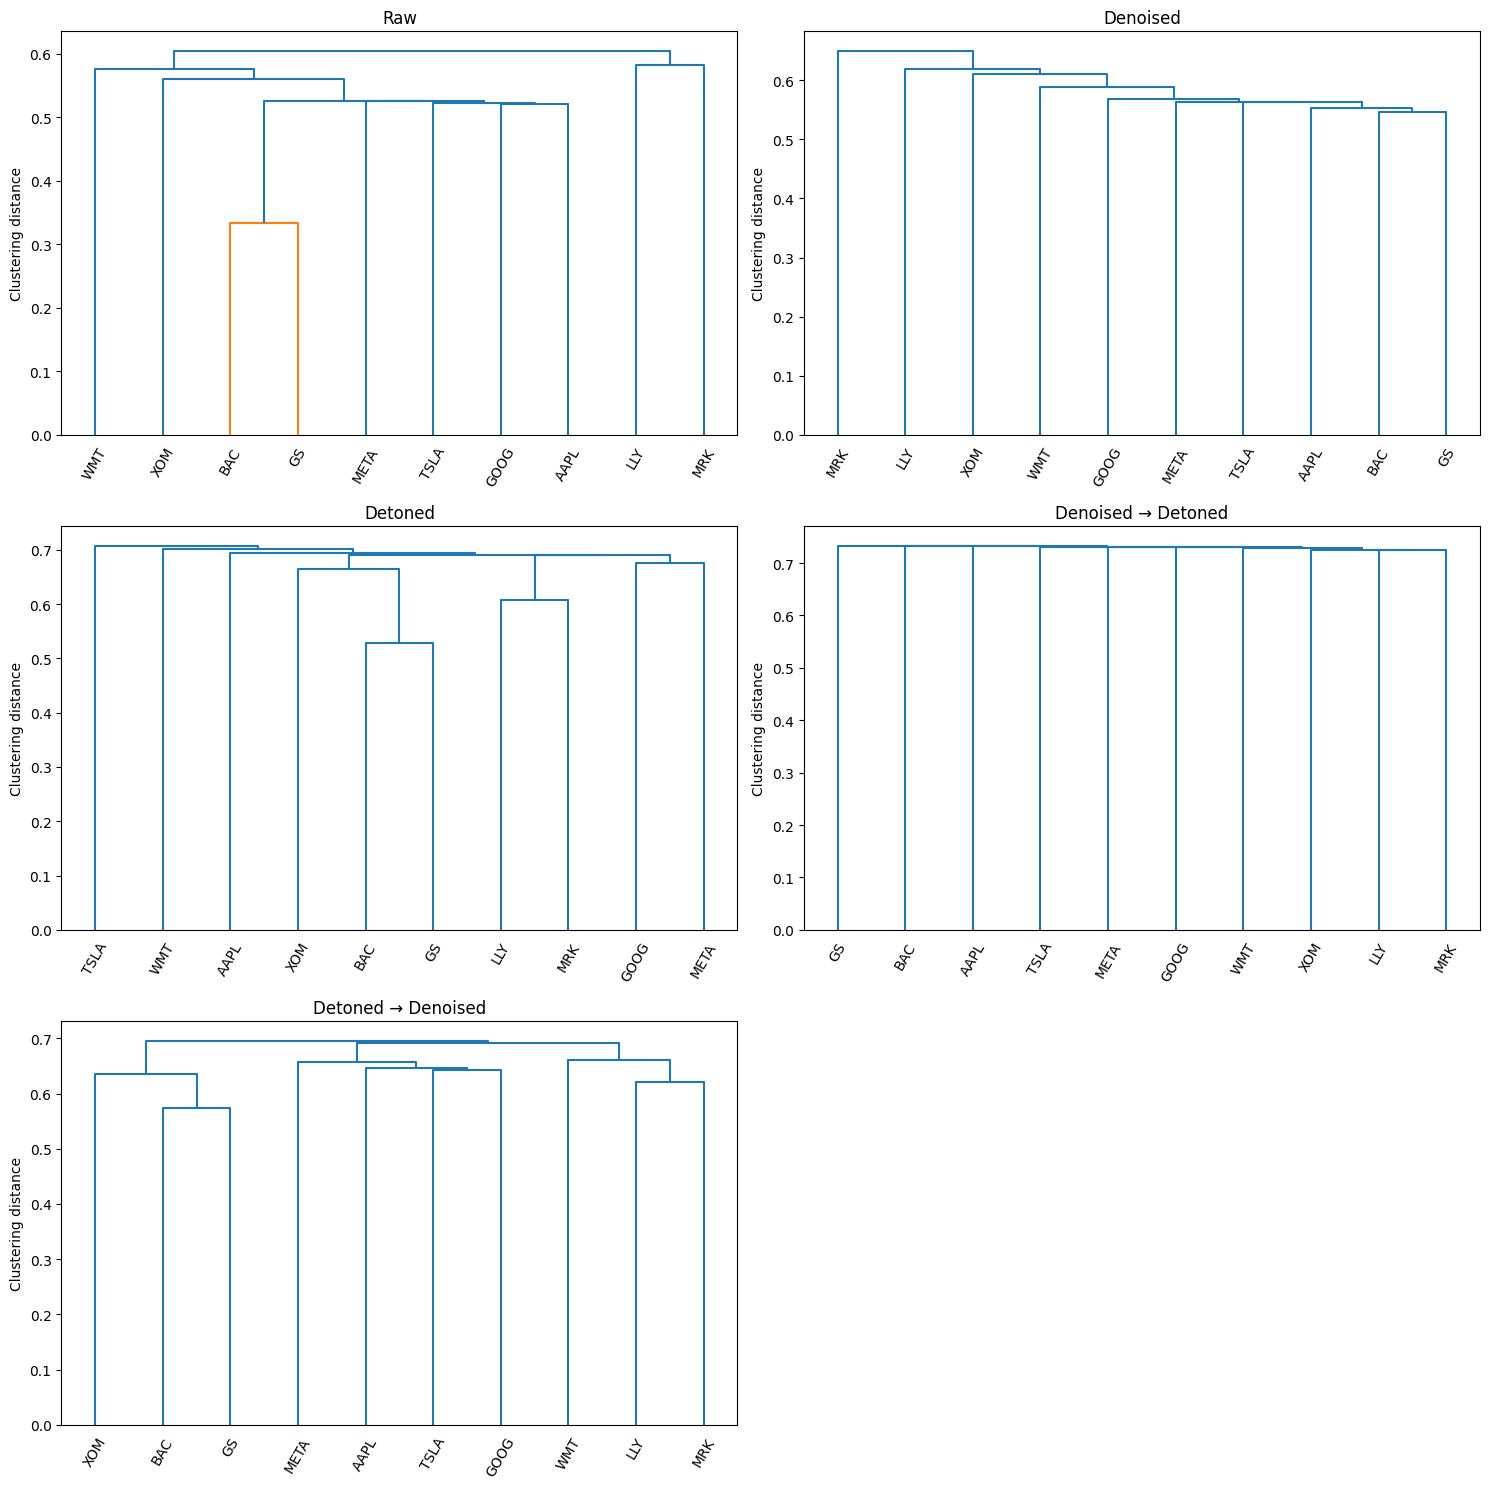

In [19]:
cluster_matrices = {
    'Raw': c_raw,
    'Denoised': c_den,
    'Detoned': c_tone,
    'Denoised → Detoned': c_dt,
    'Detoned → Denoised': c_td
}

fig, axes = plt.subplots(3, 2, figsize=(15, 15))
axes = axes.flatten()

cluster_orders = {}

for i, (name, corr) in enumerate(cluster_matrices.items()):

    z, order = cluster_linkage(corr)
    cluster_orders[name] = [tickers[j] for j in order]

    dendrogram(
        z,
        labels=tickers,
        ax=axes[i],
        leaf_rotation=60,
        leaf_font_size=10
    )

    axes[i].set_title(name)
    axes[i].set_ylabel('Clustering distance')

axes[-1].axis('off')
plt.tight_layout()
plt.show()



* In the raw correlation matrix, BAC and GS are lying close to each other. Almost every other stock; META, TSLA, GOOG, AAPL,  merges sequentially into that same cluster around 0.52–0.56.But at least here we see some clustering patterns like Healthcare; LLY and MRK,  emerge as a distinct, tight cluster at 0.58.
* In (only detoned), Financials; BAC and GS,  form the tightest cluster at 0.53, LLY and MRK were pushed to the far right edge and only joined at the very top at 0.61, Mega-Cap Tech; GOOG and META,  form their own separate pair at 0.68.
* Pure Denoised doesn't seem to form a good enough cluster. It looks like a stair case almost engulfing all assets under one big cluster.
* Surprisingly, Our  denoised and detoned matrix creates the useless cluster, stacking all assets at the same level like freaky comb bristles.
* Detoned and denoised show better clustering pattern than denoised and detoned (I never expected that I thought detoned and denoised was the best until I see these clustering pictures), but in my opinion pure Detoned show better clustering like it didn't join walmart with healthcare candidates or XOM with Financial candidates, and the lesson notes also warned about not applying denoise after detoning because it may clip the remaining eigen values after the market factor or first principal component is removed which may have removed the correct ability to cluster properly.  

In [20]:
display(pd.DataFrame({
    name: pd.Series(order)
    for name, order in cluster_orders.items()
}))


,Raw,Denoised,Detoned,Denoised → Detoned,Detoned → Denoised
0,WMT,MRK,TSLA,GS,XOM
1,XOM,LLY,WMT,BAC,BAC
2,BAC,XOM,AAPL,AAPL,GS
3,GS,WMT,XOM,TSLA,META
4,META,GOOG,BAC,META,AAPL
5,TSLA,META,GS,GOOG,TSLA
6,GOOG,TSLA,LLY,WMT,GOOG
7,AAPL,AAPL,MRK,XOM,WMT
8,LLY,BAC,GOOG,LLY,LLY
9,MRK,GS,META,MRK,MRK


## Lets get HRP weights



store all the results in a dictionary.

In [21]:
variants = {
    'Raw HRP': (c_raw, cov_raw),

    'Denoised HRP': (
        c_den, to_cov(c_den, std)
    ),

    'Detoned HRP': (
        c_tone, cov_raw
    ),

    'Denoised → Detoned → HRP': (
        c_dt, to_cov(c_den, std)
    ),

    'Detoned → Denoised → HRP': (
        c_td, to_cov(c_den, std)
    )
}

I'm going to create a function that splits the volatility to different tree splits to create our diversified portfolio.

1. Orders the stocks into a 1D list so that correlated assets sit adjacent to one another, we'll achieve this using our cluster_linkage function we defined above.
2. Then we designed it in a way that it split the stocks into different clusters and would give higher weightage to stocks that have lower volatility in that cluster and then we would calculate the variance of the whole cluster.
3. Then we would do recursive bisection: we would first start with 100% (1.0) of the capital assigned to the entire sorted list of stocks and then repeatedly slice each group in half (left and right sub-clusters) until every stock is isolated into its own bucket of size 1. At every split, it compares the variance of the left half against the right half and allocates capital inversely proportional to variance $ \alpha = \frac{V_{\text{right}}}{V_{\text{left}} + V_{\text{right}}} $. If the left group is twice as volatile as the right group, the right group gets twice as much capital.




In [22]:
def hrp_weights(corr, cov):
    corr = np.asarray(corr, dtype=float)
    cov = np.asarray(cov, dtype=float)

    z, order = cluster_linkage(corr)

    def cluster_variance(indices):
        sub_cov = cov[np.ix_(indices, indices)]
        diag = np.diag(sub_cov)

        # Inverse-variance weights within the cluster
        ivp = 1.0 / np.maximum(diag, 1e-12)
        ivp /= ivp.sum()

        return float(ivp @ sub_cov @ ivp)

    weights = np.ones(len(corr))
    clusters = [list(order)]

    # Recursive bisection
    while clusters:
        next_clusters = []

        for cluster in clusters:
            if len(cluster) <= 1:
                continue

            mid = len(cluster) // 2
            left = cluster[:mid]
            right = cluster[mid:]

            var_left = cluster_variance(left)
            var_right = cluster_variance(right)

            alpha = var_right / max(
                var_left + var_right, 1e-12
            )

            weights[left] *= alpha
            weights[right] *= (1 - alpha)

            next_clusters.extend([left, right])

        clusters = next_clusters

    weights /= weights.sum()

    return weights, z, order




The thing is hrw_weights function might put too much into low volatile stocks like 25% or 45% of capital into a single stock, so to put a cap on how much our algorithm can allocate on a single sotck we must invent another function.

our goal is to fulfil this objective:  all weights sum to 100% (1.0), and every weight lies between 0% and 20% (0.20). and our new weights need to be as close as possible to the original weights of hrw_weights.

Bisection search can solve it:

* we have to take some middle value and subtract it from every stock's weight and chop off weight if it goes beyond below 0 and above 0.2, which we can achieve with this: (np.clip(w - mid, 0, cap)) and the middle value should be adjusted such that the sum of all weights do not exceed 1 or fall short of it.



In [23]:
def cap_simplex(w, cap=0.20):
    w = np.asarray(w, dtype=float).copy()
    n = len(w)

    if cap <= 0 or n * cap < 1 - 1e-12:
        raise ValueError("Infeasible cap: n * cap must be >= 1.")

    if not np.all(np.isfinite(w)):
        raise ValueError("Weights must be finite.")

    # Euclidean projection onto:
    # sum(w) = 1 and 0 <= w_i <= cap
    lo = np.min(w - cap)
    hi = np.max(w)

    for _ in range(200):
        mid = (lo + hi) / 2
        projected = np.clip(w - mid, 0, cap)

        if projected.sum() > 1:
            lo = mid
        else:
            hi = mid

    result = np.clip(w - (lo + hi) / 2, 0, cap)

    assert np.isclose(result.sum(), 1, atol=1e-8)
    assert np.all(result >= -1e-10)
    assert np.all(result <= cap + 1e-10)

    return result

lets put them all together for our portfolio.

,TSLA,WMT,BAC,GS,LLY,MRK,GOOG,META,AAPL,XOM
Raw HRP,2.27,20.00,8.98,4.95,6.15,12.41,10.76,2.94,12.33,19.21
Denoised HRP,1.89,16.50,8.10,6.18,8.30,16.78,8.48,5.71,8.56,19.49
Detoned HRP,2.39,20.00,9.90,10.32,6.67,14.95,7.61,4.84,10.23,13.09
Denoised → Detoned → HRP,1.19,19.32,10.26,7.83,6.78,13.71,9.93,3.58,7.60,19.82
Detoned → Denoised → HRP,2.28,20.00,12.33,8.03,6.94,13.91,10.49,3.66,6.03,16.33


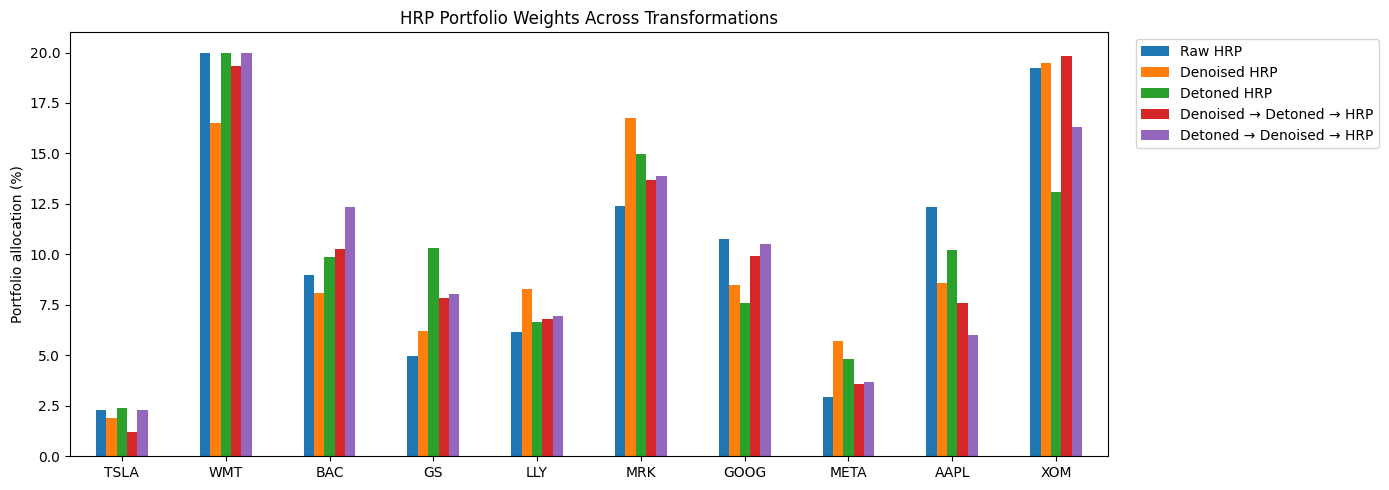

In [24]:
hrp_results = {}

for name, (clustering_corr, risk_cov) in variants.items():

    w, z, order = hrp_weights(
        clustering_corr, risk_cov
    )

    # Apply the 20% cap
    w = cap_simplex(w, cap=0.20)
    hrp_results[name] = w

weights_table = pd.DataFrame(
    hrp_results, index=tickers
).T

display((weights_table * 100).round(2))

# Validate allocations
assert np.allclose(weights_table.sum(axis=1), 1)
assert (weights_table.values >= -1e-8).all()
assert (weights_table.values <= 0.20 + 1e-8).all()

# Plot
(weights_table.T * 100).plot(
    kind='bar',
    figsize=(14, 5)
)

plt.ylabel('Portfolio allocation (%)')
plt.title('HRP Portfolio Weights Across Transformations')
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


HRP across all those different transformations of our correlation matrices, allocates 48% to 53% of capital in low-volatility groceries, healthcare, and energy like WMT, MRK, and XOM, but  limits the allocation to high volatile stocks like  TSLA 1.19%–2.39%, and META: 2.94%–5.71%. WMT repeatedly hits the 20.00% maximum position cap, demonstrating the necessity of our cap_simplex function to prevent single-stock concentration. The most important thing to note here is Detoned HRP produces more balanced sector diversification than Raw HRP: isolating Financials into a clean cluster lifts GS from 4.95% to 10.32% and BAC from 8.98% to 9.90%, while trimming XOM from 19.21% to 13.09%. And Denoised $\rightarrow $ Detoned $ \rightarrow $ HRP reverts closely to raw inverse-variance weights 19.32% WMT, 19.82% XOM because its flattened piano-keys resembling dendrogram lacks meaningful cluster splits I guess.


let's now set the raw correlation matrix as our baseline and compare every other variants with it to see how much they deviate from it.

plan:
1. get the Raw HRP as the baseline.
2. calculate the weight change of each of our transformed correlation matrices in relation to the raw
3. calculate Annualized volatility of each.
4. calculate the inverse Herfindahl-Hirschman Index a.k.a effective asset, the higher this number the more diversified that portfolio is.
5. and finally we will also compute largest weight, this is just to check whether w.max() of any of variants have reached the 0.20, 20%,  cap enforced earlier by cap_simplex function.

In [25]:
baseline = weights_table.loc['Raw HRP'].to_numpy()

comparison_results = []

for method, row in weights_table.iterrows():

    w = row.to_numpy()

    turnover_from_raw = 0.5 * np.abs(w - baseline).sum()

    annual_vol = np.sqrt(
        w @ cov_raw @ w * 252
    )

    effective_assets = 1 / np.sum(w**2)

    comparison_results.append({
        'Method': method,
        'Weight_Change_vs_Raw': turnover_from_raw,
        'Annualized_Volatility': annual_vol,
        'Effective_Assets': effective_assets,
        'Largest_Weight': w.max()
    })

allocation_diagnostics = pd.DataFrame(
    comparison_results
).set_index('Method')

display(allocation_diagnostics.round(4))


,Weight_Change_vs_Raw,Annualized_Volatility,Effective_Assets,Largest_Weight
Method,,,,
Raw HRP,0.0000,0.1525,7.4207,0.2000
Denoised HRP,0.1080,0.1513,7.7647,0.1949
Detoned HRP,0.1138,0.1574,8.0941,0.2000
Denoised → Detoned → HRP,0.0733,0.1497,7.4800,0.1982
Detoned → Denoised → HRP,0.0945,0.1531,7.7532,0.2000


Detoned HRP offers the highest diversification with effective_assets value being 8.0941, and its portfolio is also having high volatility compared to the baseline perhaps it is due to it trying to move from allocating more capital on low beta defensive stocks such as XOM to spreading it to financial and market moving investment bank stocks; XOM drops from 19.21% to 13.09%, GS rises to 10.32%. And the volatility increase is also very modest like 0.49% for a better diversification. Weight_change_vs_RAW on detoned has 11.38% away from Raw, so removing the PC1 had given some boost in terms of hierarchical clustering and better portfolio allocation. I choose to talk only about detoned here because I find the other variants not very interesting based on effective_assets measure here and also factoring in the fact that pure Detoned provided better hierarchical clustering than others.

# Step 6: Out-of-Sample Performance check

we are going to test all of our five combinations: raw, denoised HRP, detoned HRP, denoised -> detoned -> HRP, detoned -> denoised -> HRP and report which of them best performed in out-of-sample data.

I'll also compare these against the traditional Kelly portfolio from Step 1, once my teammate Duy's final weights are available.

let's prepare the out-of-sample returns first to fist.


## Prepare out-of-sample returns

In [26]:
test = returns_out_sample.loc[
    '2025-10-01':'2025-12-31', tickers
].copy()

assert list(test.columns) == list(tickers)
assert not test.isna().any().any()
assert len(test) > 0
assert np.isfinite(test.to_numpy()).all()

print("Out-of-sample observations:", len(test))
print("Testing period:", test.index.min(), "to", test.index.max())
print("Number of assets:", test.shape[1])

display(test.head())


Out-of-sample observations: 64
Testing period: 2025-10-01 00:00:00 to 2025-12-31 00:00:00
Number of assets: 10


Ticker,TSLA,WMT,BAC,GS,LLY,MRK,GOOG,META,AAPL,XOM
Date,,,,,,,,,,
2025-10-01,0.033144,-0.010673,-0.017639,-0.013612,0.081809,0.073871,0.008171,-0.023203,0.003220,-0.006741
2025-10-02,-0.051060,-0.002550,-0.003946,-0.007804,-0.006748,-0.006879,0.003625,0.013536,0.006577,-0.006251
2025-10-03,-0.014151,0.003638,0.003170,0.013601,0.024419,-0.003575,0.000081,-0.022681,0.003461,0.017702
2025-10-06,0.054487,0.006172,-0.004937,0.008608,0.006168,-0.004373,0.020532,0.007177,-0.005155,0.008299
2025-10-07,-0.044479,0.005258,-0.001984,-0.008949,-0.001680,-0.013401,-0.017415,-0.003605,-0.000818,0.000525


I'm not going to use these out-of-sample returns to calculate covariance matrix or detemine clusteres, optimize weights, or select the best strategy for evaluation like with our training data.

some prior assumptions(which later will be tweaked and adjusted reflecting reality closely):

1. Daily rebalancing to fixed target weights.
2. zero transcation costs.
3. a zero risk-free rate
4. All strategies treated alike (I have some extra trust on detoned though).



## Calculate portfolio returns

* we'll just multiply the individual asset's return and proportion of money invested in them which we call weights and sum for all assets to get our portfolio returns.
* we already have weights_table from Step 5, containing one row of asset weights for each HRP strategy.
* We need to make sure three things the weights of all assets must sum to 1, the weights of all assets must be greater than or equal to 0, weights of any asset must not exceed the 20% threshold.
* Cross-check the first column which is Raw HRP of the 2D matrix multiplication against a direct 1D dot product (test @ w_0) to confirm there were no transpose or broadcasting mistakes.


In [27]:

# weights_table: rows = strategies, columns = tickers
weights = weights_table.loc[:, tickers].copy()

assert np.allclose(weights.sum(axis=1), 1, atol=1e-8)
assert (weights.to_numpy() >= -1e-8).all()
assert (weights.to_numpy() <= 0.20 + 1e-8).all()

# Each strategy holds constant weights, rebalanced daily
portfolio_returns = pd.DataFrame(
    test.to_numpy() @ weights.to_numpy().T,
    index=test.index,
    columns=weights.index
)

display(portfolio_returns.head())

# Verify calculation for the first strategy
first_strategy = weights.index[0]

assert np.allclose(
    portfolio_returns[first_strategy],
    test.to_numpy() @ weights.loc[first_strategy].to_numpy()
)


,Raw HRP,Denoised HRP,Detoned HRP,Denoised → Detoned → HRP,Detoned → Denoised → HRP
Date,,,,,
2025-10-01,0.009853,0.014108,0.010953,0.010017,0.010403
2025-10-02,-0.003279,-0.003479,-0.003621,-0.003410,-0.003964
2025-10-03,0.005591,0.005316,0.004780,0.006060,0.005362
2025-10-06,0.005670,0.005289,0.005166,0.005374,0.005843
2025-10-07,-0.004324,-0.004727,-0.004763,-0.004183,-0.004831


This is the one daily-return time series per strategy.

Now I have look at Duy's kelly portfolio and take the weight vector he'd calculated.

he has got this:

In [31]:
df_step1_weights.round(3)

,Unconstrained Raw,Unconstrained Normalized (%),Constrained (w_i <= 20%) (%)
TSLA,-0.222,-2.248,20.0
WMT,7.867,79.576,20.0
BAC,-2.148,-21.723,-0.0
GS,4.582,46.343,20.0
LLY,0.644,6.509,-0.0
MRK,-2.952,-29.862,-0.0
GOOG,2.207,22.325,20.0
META,1.116,11.287,20.0
AAPL,-2.020,-20.432,0.0
XOM,0.813,8.224,-0.0


we have to take constrained below 20% weights which is the third column here and to be frank I don't like the lengthy name he or his AI chose for that so I'm going to shorted it to 'weights' and store it in kelly weights variable.

* Convert 20.0% -> 0.20 decimal scale, right now he has used plain float like 20.
* clip the floating artifacts or any negatives.
* reindex the series with the tickers name
* rename the column as weights.

In [34]:
kelly_weights = (
    df_step1_weights['Constrained (w_i <= 20%) (%)']
    .div(100)
    .clip(lower=0.0)
    .reindex(tickers)
    .rename('weights')
).round(3)

kelly_weights

,weights
TSLA,0.2
WMT,0.2
BAC,0.0
GS,0.2
LLY,0.0
MRK,0.0
GOOG,0.2
META,0.2
AAPL,0.0
XOM,0.0


Nice!

In [35]:
kelly = kelly_weights.reindex(tickers)
assert not kelly.isna().any()
assert np.isclose(kelly.sum(), 1)

portfolio_returns['Traditional Kelly'] = (
    test.to_numpy() @ kelly.to_numpy()
)


In [36]:
portfolio_returns.head(5)

,Raw HRP,Denoised HRP,Detoned HRP,Denoised → Detoned → HRP,Detoned → Denoised → HRP,Traditional Kelly
Date,,,,,,
2025-10-01,0.009853,0.014108,0.010953,0.010017,0.010403,-0.001235
2025-10-02,-0.003279,-0.003479,-0.003621,-0.003410,-0.003964,-0.008851
2025-10-03,0.005591,0.005316,0.004780,0.006060,0.005362,-0.003902
2025-10-06,0.005670,0.005289,0.005166,0.005374,0.005843,0.019395
2025-10-07,-0.004324,-0.004727,-0.004763,-0.004183,-0.004831,-0.013838


## How will we check which allocation performs better in out-of-sample data?

we will specifically use 6 metrics they are:
* cumulative returns $ \prod_{t=1}^T(1+R_{p,t})-1 $, the higher it is the better our portfolio weights are.
* sharpe ratio: $ \sqrt{252}\,\bar R_p/s_p $ this is annualized sharpe ratio, the higher sharpe indicates better portfolio.
* Annualized volatility: $ \sqrt{252}\,s_p $ the lower the beter.
* Maximum drawdown: $ \min_t(V_t/\max_{s\leq t}V_s-1)\ $ which is the largest fall from the sky (in terms of stock price climbing adventures ofcourse), the closer this value to zero less number of bones break.
* 95% cvar: $ -E[R_p\mid R_p\leq q_{0.05}] $, lower the better. For our purpose, CVaR measures the average loss among the worst 5% of observed daily returns. It is a historical tail-loss estimate.
* sortino ratio: Annualized mean excess return / downside deviation, it needs to be higher.


In [37]:
TRADING_DAYS = 252
RISK_FREE_ANNUAL = 0.0

def performance_metrics(r, risk_free_annual=0.0):
    r = pd.Series(r, dtype=float).dropna()

    if len(r) < 2:
        raise ValueError("At least two returns are required.")

    if not np.isfinite(r).all():
        raise ValueError("Returns must be finite.")

    if (r <= -1).any():
        raise ValueError("Daily return cannot be <= -100%.")

    daily_rf = (1 + risk_free_annual)**(1/TRADING_DAYS) - 1

    excess = r - daily_rf

    # Wealth index, starting at 1
    wealth = (1 + r).cumprod()
    wealth_with_initial = pd.concat([
        pd.Series([1.0]), wealth.reset_index(drop=True)
    ], ignore_index=True)

    running_peak = wealth_with_initial.cummax()
    drawdown = wealth_with_initial / running_peak - 1

    # Cumulative return
    cumulative_return = wealth.iloc[-1] - 1

    # Annualized volatility
    daily_vol = r.std(ddof=1)
    annualized_vol = daily_vol * np.sqrt(TRADING_DAYS)

    # Annualized Sharpe ratio
    sharpe = (
        excess.mean() / daily_vol * np.sqrt(TRADING_DAYS)
        if daily_vol > 0 else np.nan
    )

    # Maximum drawdown
    max_drawdown = drawdown.min()

    # 95% historical CVaR: average loss in worst 5%
    q05 = r.quantile(0.05)
    tail_returns = r[r <= q05]
    cvar_95 = -tail_returns.mean()

    # Sortino ratio, zero-target downside deviation
    downside = np.minimum(excess.to_numpy(), 0)
    downside_deviation = np.sqrt(np.mean(downside**2))

    sortino = (
        excess.mean() / downside_deviation * np.sqrt(TRADING_DAYS)
        if downside_deviation > 0 else np.nan
    )

    return {
        'Cumulative_Return': cumulative_return,
        'Sharpe_Ratio': sharpe,
        'Annualized_Volatility': annualized_vol,
        'Maximum_Drawdown': max_drawdown,
        'CVaR_95': cvar_95,
        'Sortino_Ratio': sortino
    }


step6_metrics = pd.DataFrame({
    name: performance_metrics(portfolio_returns[name],
                              RISK_FREE_ANNUAL)
    for name in portfolio_returns.columns
}).T

# Report-friendly percentage format
step6_table = step6_metrics.copy()

pct_columns = [
    'Cumulative_Return',
    'Annualized_Volatility',
    'Maximum_Drawdown',
    'CVaR_95'
]

step6_table[pct_columns] *= 100

display(step6_table.round(4))


,Cumulative_Return,Sharpe_Ratio,Annualized_Volatility,Maximum_Drawdown,CVaR_95,Sortino_Ratio
Raw HRP,13.4903,4.6859,10.7656,-3.1250,1.2757,8.1917
Denoised HRP,14.0046,4.6953,11.1326,-3.0022,1.2669,8.3961
Detoned HRP,13.3143,4.4613,11.1805,-3.0443,1.2691,7.9266
Denoised → Detoned → HRP,13.7877,4.7499,10.8398,-3.0056,1.2707,8.3021
Detoned → Denoised → HRP,13.9622,4.6741,11.1522,-3.0535,1.2938,8.2199
Traditional Kelly,7.8828,1.6508,19.2078,-6.5192,2.4688,2.5184
